<a href="https://colab.research.google.com/github/plasmidinductance-sketch/Seizure-analysis-using-Bonn-data/blob/main/bonn_epilepsy_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# importing libraries

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
from scipy.signal import butter, filtfilt

In [ ]:
from google.colab import files
multiple_uploaded = files.upload()

Saving setA_bonn.xls to setA_bonn.xls
Saving setB_bonn.xls to setB_bonn (1).xls
Saving setC_bonn.xls to setC_bonn (1).xls
Saving setD_bonn-1.xls to setD_bonn-1 (1).xls
Saving setE_bonn.xls to setE_bonn (1).xls


In [ ]:
df1=pd.read_excel('/content/setA_bonn.xls')
df2=pd.read_excel('/content/setB_bonn.xls')
df3=pd.read_excel('/content/setC_bonn.xls')
df4=pd.read_excel('/content/setD_bonn-1.xls')
df5=pd.read_excel('/content/setE_bonn.xls')

In [ ]:
df1.head()

,12,-56,-37,-31,14,-87,-2,-31.1,8,-41,...,13.1,40.1,-19.2,-45.1,6.1,-133,-3,-51,56,-36
0,22,-50,-22,-43,26,-89,20,-16,17,-38,...,30,48,-1,-62,-6,-144,-3,-42,55,-71
1,35,-64,-17,-39,32,-73,42,10,29,-31,...,42,35,33,-76,-8,-113,-12,-39,38,-120
2,45,-91,-24,-39,25,-69,48,28,46,-25,...,56,5,51,-98,-6,-74,-24,-47,-5,-150
3,69,-135,-31,-9,16,-51,27,31,50,-32,...,56,-40,49,-108,15,-41,-34,-51,-47,-160
4,74,-140,-20,-5,8,-48,11,8,44,-27,...,59,-54,26,-106,27,-41,-42,-46,-72,-133


# plotting signals

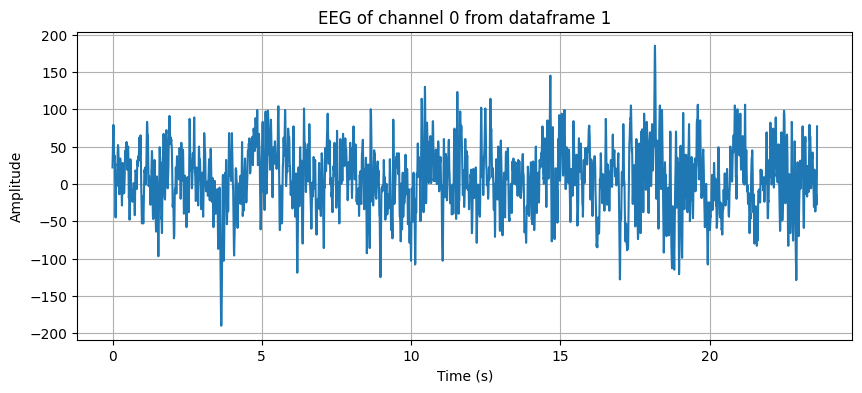

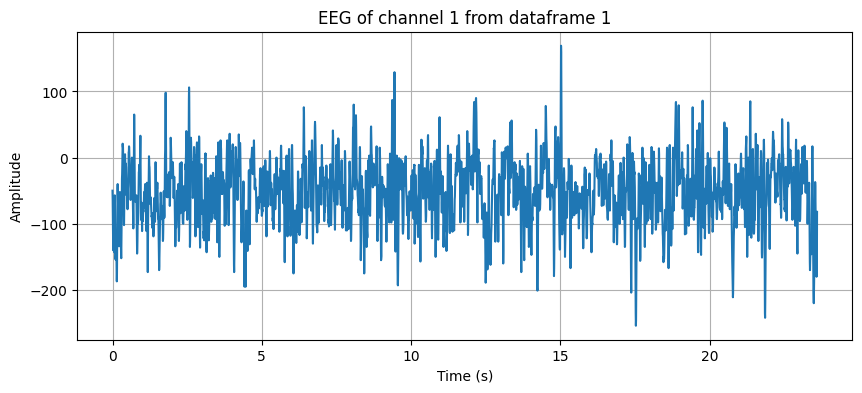

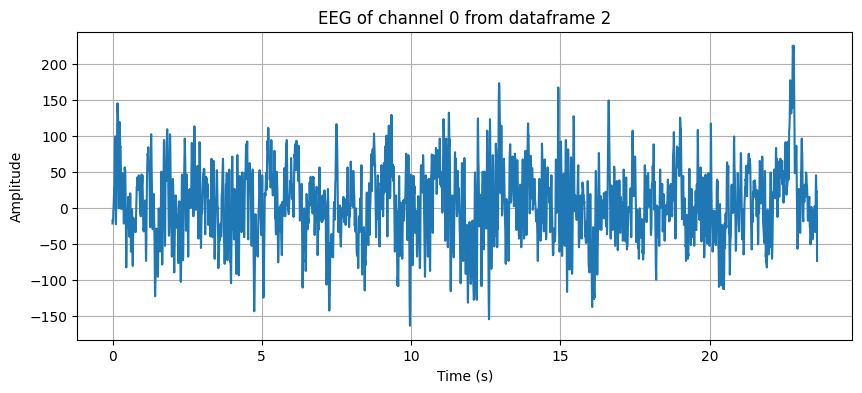

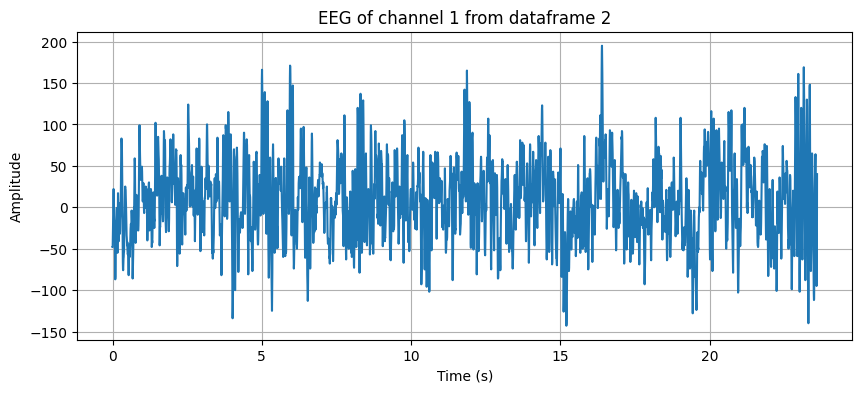

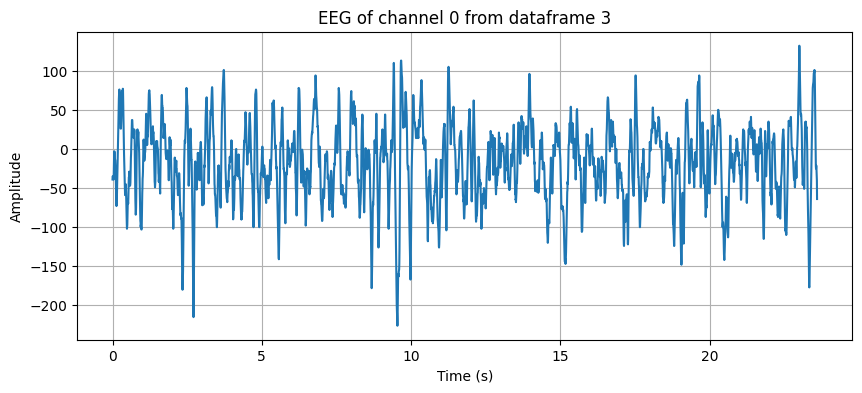

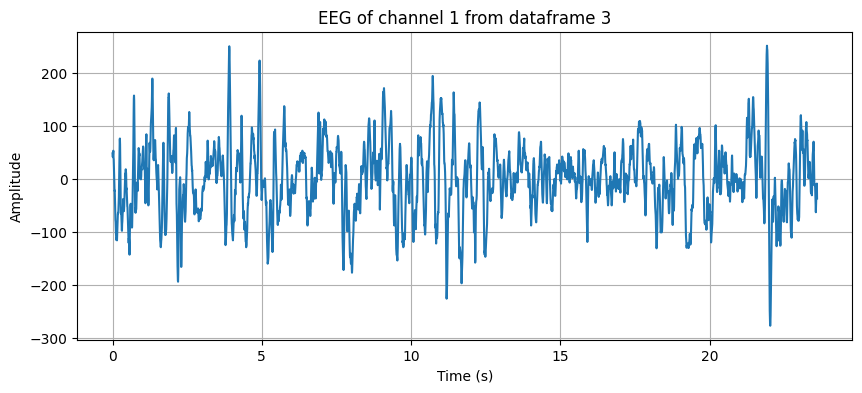

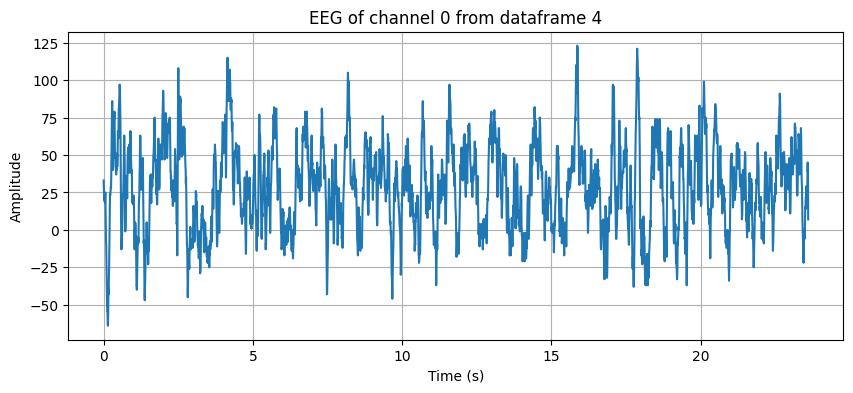

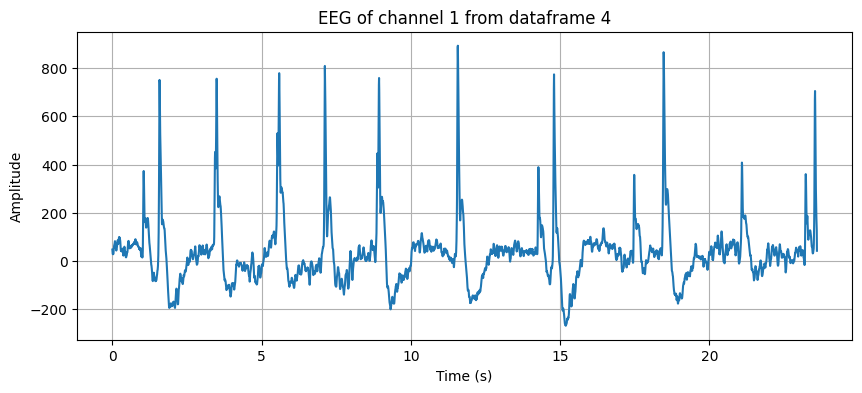

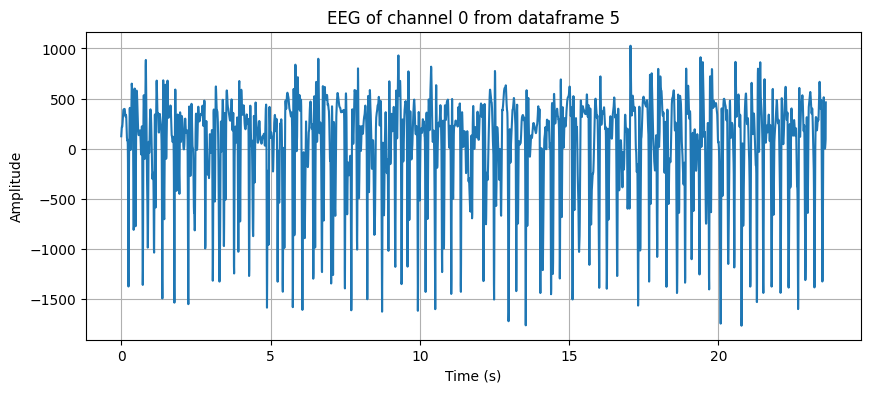

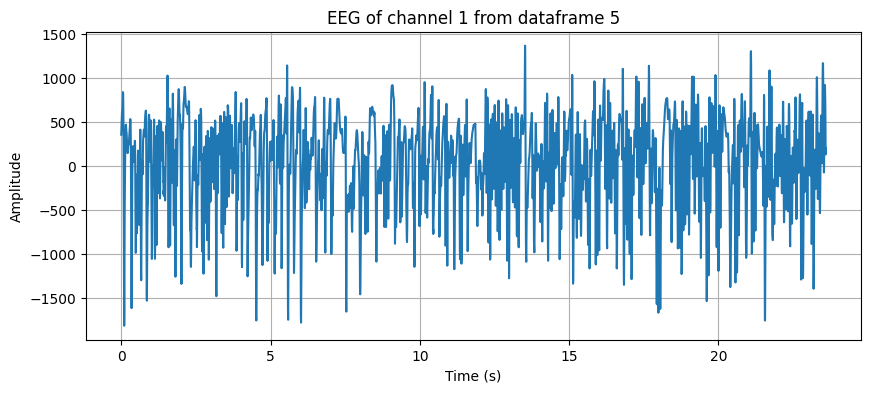

In [ ]:
for a in range(1,6):
 for ch in range(0,2):
  df_current = globals()[f'df{a}']
  person_column = df_current.iloc[:, ch]
  time = np.linspace(0, 23.6, len(person_column))
  plt.figure(figsize=(10,4))
  plt.plot(time, person_column.values)
  plt.xlabel("Time (s)")
  plt.ylabel("Amplitude")
  plt.title(f"EEG of channel {ch} from dataframe {a}")
  plt.grid(True)
  plt.show()

# classification of set (A & E)


In [ ]:
x_raw = np.vstack((df1.values.T, df5.values.T))
y = np.array([0]*100 + [1]*100)

### signal preprocessing

In [ ]:
def bandpass_filter(signal, lowcut=0.5, highcut=40, fs=173.6, order=4):
    nyq = fs / 2
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal)

X_filtered = np.array([bandpass_filter(sig) for sig in x_raw])

In [ ]:
from sklearn.preprocessing import StandardScaler
X_normalized = np.array([(sig - sig.mean()) / sig.std() for sig in X_filtered])

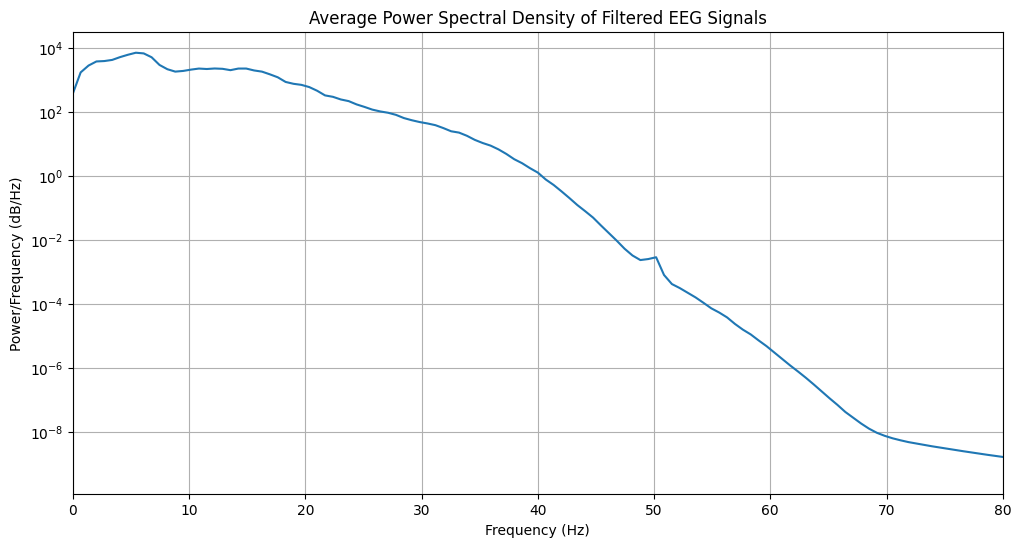

In [ ]:
from scipy.signal import welch
fs = 173.6
freqs, psd = welch(X_filtered, fs=fs, nperseg=256)
plt.figure(figsize=(12, 6))
plt.semilogy(freqs, psd.mean(axis=0))
plt.title('Average Power Spectral Density of Filtered EEG Signals')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')
plt.grid(True)
plt.xlim([0, 80])
plt.show()

In [ ]:
from scipy.signal import iirnotch

def notch_filter(signal, freq=50, fs=173.6, quality=30):
    b, a = iirnotch(freq / (fs/2), quality)
    return filtfilt(b, a, signal)

X_filtered_notched = np.array([notch_filter(sig, freq=50, fs=173.6, quality=30) for sig in X_filtered])


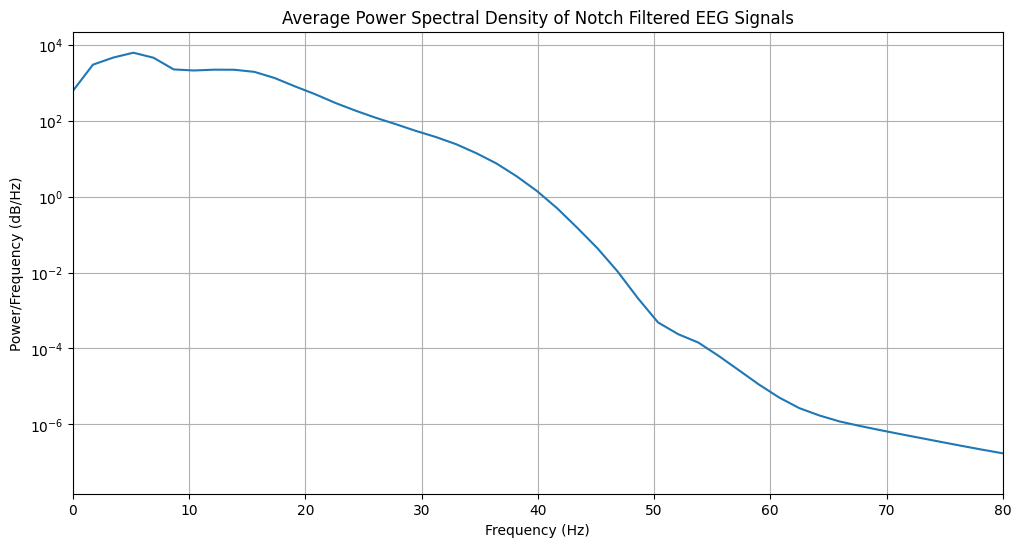

In [ ]:
freqs_notched, psd_notched = welch(X_filtered_notched, fs=fs, nperseg=100)
plt.figure(figsize=(12, 6))
plt.semilogy(freqs_notched, psd_notched.mean(axis=0))
plt.title('Average Power Spectral Density of Notch Filtered EEG Signals')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')
plt.grid(True)
plt.xlim([0, 80])
plt.show()

# windowing of signal

### feature engineering

In [ ]:
def signal_energy(window):
    return np.sum(window ** 2)

In [ ]:
from scipy.stats import skew, kurtosis

def time_features(signal):
    return [
        np.mean(signal),
        np.std(signal),
        np.var(signal),
        skew(signal),
        kurtosis(signal),
        np.sqrt(np.mean(signal**2)),
        np.max(signal) - np.min(signal),
        signal_energy(signal)
    ]

In [ ]:
data=[]
for i in range(len(X_filtered_notched)):
  signal=X_filtered_notched[i]
  features=time_features(signal)
  label=y[i]

  data.append(features+[label])
features_df=pd.DataFrame(data,columns=['mean','std','varience','skewness','kurtosis','rms','peak','total_energy','label'])
display(features_df.head())
print(features_df.shape)

,mean,std,varience,skewness,kurtosis,rms,peak,total_energy,label
0,-0.360134,40.563410,1645.390210,-0.150991,0.327092,40.565008,328.978430,6.740050e+06,0
1,-1.072408,48.241144,2327.207932,-0.132281,0.597998,48.253062,416.393738,9.536954e+06,0
2,-0.062764,45.424222,2063.359979,-0.069982,0.196086,45.424266,354.096770,8.451539e+06,0
3,0.044024,45.552769,2075.054770,0.025341,0.314736,45.552790,355.350118,8.499432e+06,0
4,-0.213749,41.718111,1740.400817,-0.050573,0.395613,41.718659,315.980561,7.128869e+06,0


(200, 9)


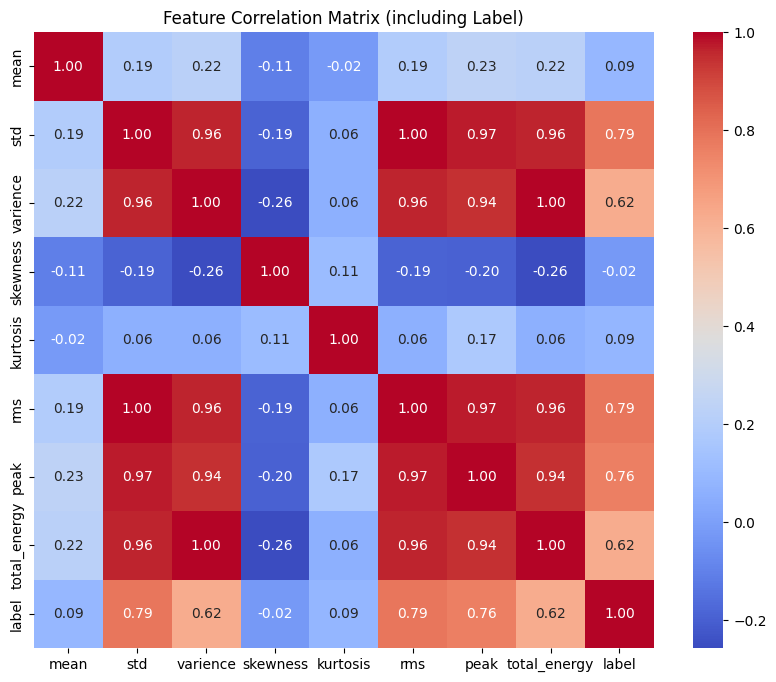

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
corr = features_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Matrix (including Label)')
plt.show()

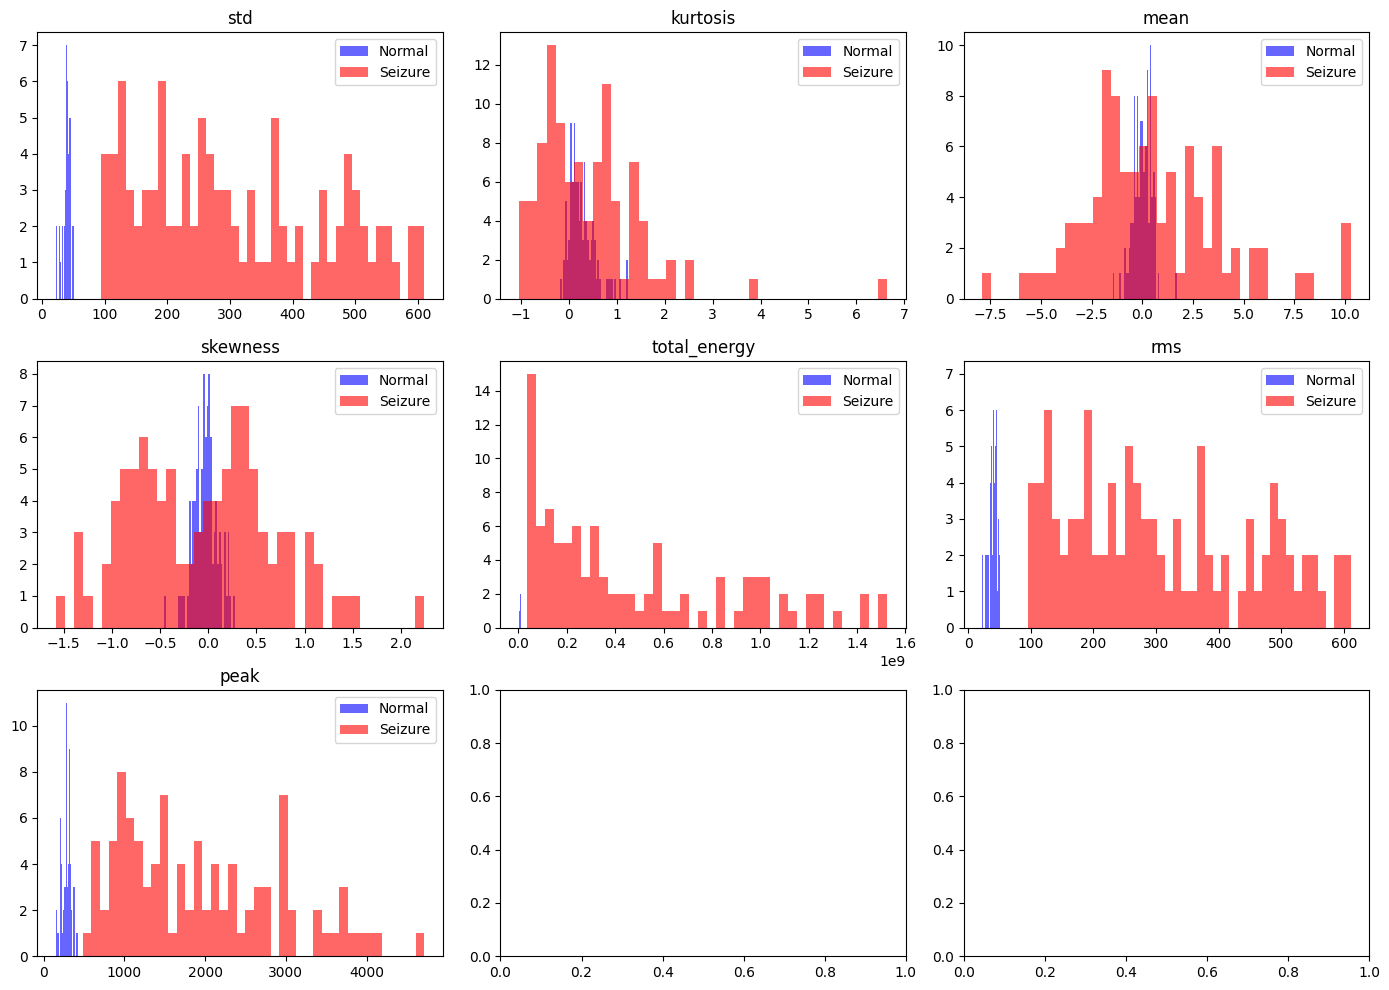

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

features_to_check = [
    'std', 'kurtosis', 'mean','skewness',
     'total_energy',
    'rms', 'peak'
]

for i, feat in enumerate(features_to_check):
    normal  = features_df[features_df['label'] == 0][feat]
    seizure = features_df[features_df['label'] == 1][feat]

    axes[i].hist(normal,  bins=40, alpha=0.6, label='Normal',  color='blue')
    axes[i].hist(seizure, bins=40, alpha=0.6, label='Seizure', color='red')
    axes[i].set_title(feat)
    axes[i].legend()

plt.tight_layout()
plt.show()

### Linear Regression

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = features_df.drop(['label','kurtosis','mean','skewness'], axis=1)
y = features_df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preparation complete:")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"\nModel: Logistic Regression")
print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:")
print(report)

Data preparation complete:
X_train_scaled shape: (140, 5)
X_test_scaled shape: (60, 5)
y_train shape: (140,)
y_test shape: (60,)

Model: Logistic Regression
Accuracy: 1.0000
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



### SVM

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report
svm_model=SVC(kernel='rbf',random_state=42)
svm_model.fit(X_train_scaled,y_train)
y_pred=svm_model.predict(X_test_scaled)
accuracy=accuracy_score(y_test,y_pred)
report=classification_report(y_test,y_pred)
print(f"\nModel:SVM")
print(f"Accuracy:{accuracy:.4f}")
print("Classification Report:")
print(report)



Model:SVM
Accuracy:1.0000
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        30

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



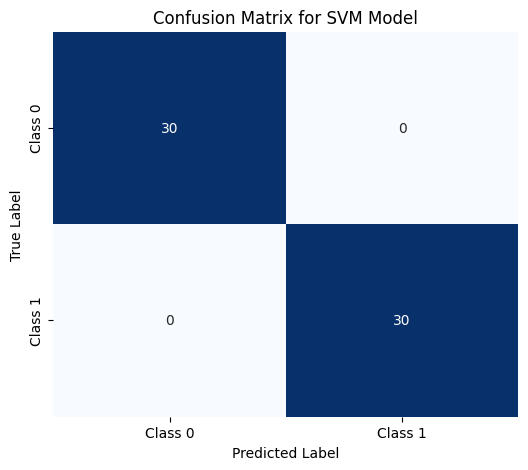

Confusion Matrix for SVM:
 [[30  0]
 [ 0 30]]


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for SVM Model')
plt.show()

print("Confusion Matrix for SVM:\n", cm_svm)

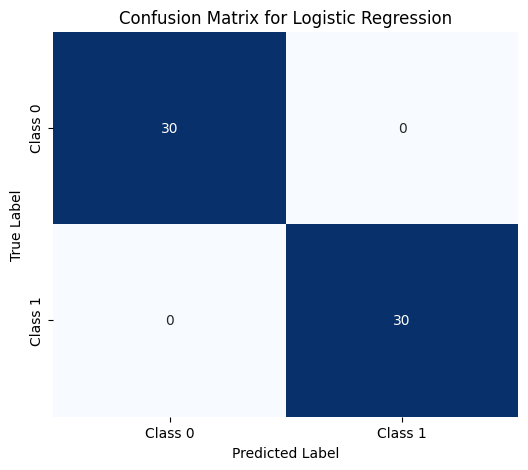

Confusion Matrix:
 [[30  0]
 [ 0 30]]


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

print("Confusion Matrix:\n", cm)

### Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
scaler_cv = StandardScaler()
X_scaled_cv = scaler_cv.fit_transform(X)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#### Logistic Regression Cross-Validation

In [ ]:
log_reg_model_cv = LogisticRegression(random_state=42)
cv_scores_log_reg = cross_val_score(log_reg_model_cv, X_scaled_cv, y, cv=skf, scoring='accuracy')

print("Logistic Regression Cross-Validation Scores:", cv_scores_log_reg)
print(f"Mean Accuracy (Logistic Regression): {cv_scores_log_reg.mean():.4f}")
print(f"Standard Deviation (Logistic Regression): {cv_scores_log_reg.std():.4f}")

Logistic Regression Cross-Validation Scores: [1.    0.975 1.    0.95  1.   ]
Mean Accuracy (Logistic Regression): 0.9850
Standard Deviation (Logistic Regression): 0.0200


#### SVM Cross-Validation

In [ ]:
svm_model_cv = SVC(kernel='rbf', random_state=42)
cv_scores_svm = cross_val_score(svm_model_cv, X_scaled_cv, y, cv=skf, scoring='accuracy')

print("SVM Cross-Validation Scores:", cv_scores_svm)
print(f"Mean Accuracy (SVM): {cv_scores_svm.mean():.4f}")
print(f"Standard Deviation (SVM): {cv_scores_svm.std():.4f}")

SVM Cross-Validation Scores: [1. 1. 1. 1. 1.]
Mean Accuracy (SVM): 1.0000
Standard Deviation (SVM): 0.0000


# 2nd classification (A,B & C,D,E)

### time domain classification

In [ ]:
x_raw1=np.vstack((df1.values.T,df2.values.T,df3.values.T,df4.values.T,df5.values.T))
y1=np.array([0]*200+[1]*300)

In [ ]:
X_filtered1 = np.array([bandpass_filter(sig) for sig in x_raw1])

In [ ]:
X_normalized1 = np.array([(sig - sig.mean()) / sig.std() for sig in X_filtered1])

In [ ]:
X_filtered_notched1= np.array([notch_filter(sig, freq=50, fs=173.6, quality=30) for sig in X_filtered1])

### windowing

In [ ]:
window_size_sec = 1
window_size = int(fs * window_size_sec) # fs is defined as 173.6

# Using 50% overlap
overlap_sec = 0.5
overlap_samples = int(fs * overlap_sec)
step_size = window_size - overlap_samples

X_windowed = []
y_windowed = [] # Keep track of labels for each window

for i, signal in enumerate(X_filtered_notched1):
    signal_label = y1[i] # y1 contains labels for X_filtered_notched1
    num_samples = len(signal)

    # Iterate with a sliding window
    for start in range(0, num_samples - window_size + 1, step_size):
        end = start + window_size
        window = signal[start:end]
        X_windowed.append(window)
        y_windowed.append(signal_label)

X_windowed = np.array(X_windowed)
y_windowed = np.array(y_windowed)

print(f"Original number of signals: {len(X_filtered_notched1)}")
print(f"Number of windows generated: {len(X_windowed)}")
print(f"Shape of windowed data: {X_windowed.shape}")
print(f"Shape of windowed labels: {y_windowed.shape}")

Original number of signals: 500
Number of windows generated: 23000
Shape of windowed data: (23000, 173)
Shape of windowed labels: (23000,)


In [ ]:
data1=[]
for i in range(len(X_windowed)):
  signal=X_windowed[i]
  features=time_features(signal)
  label=y_windowed[i]

  data1.append(features+[label])
features_df1=pd.DataFrame(data1,columns=['mean','std','varience','skewness','kurtosis','rms','peak','total_energy','label'])
display(features_df1.head())
print(features_df1.shape)

,mean,std,varience,skewness,kurtosis,rms,peak,total_energy,label
0,1.695025,28.563592,815.878764,-0.054984,-0.756096,28.613841,124.615725,141644.074348,0
1,-1.203154,32.818686,1077.066153,0.234455,-0.569209,32.840733,144.957686,186582.875879,0
2,3.850734,40.568673,1645.817204,-0.179674,-0.653110,40.751017,181.567837,287291.646526,0
3,-3.294509,40.452405,1636.397107,-0.186441,-0.619693,40.586339,180.102322,284974.404947,0
4,-5.059396,31.332359,981.716702,-0.124516,0.280963,31.738213,168.455590,174265.354175,0


(23000, 9)


#### plottings

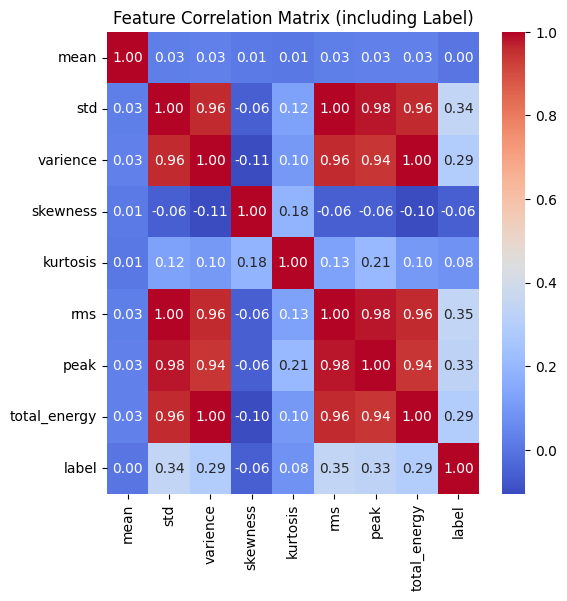

In [ ]:
corr1 = features_df1.corr()

plt.figure(figsize=(6, 6))
sns.heatmap(corr1, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Matrix (including Label)')
plt.show()

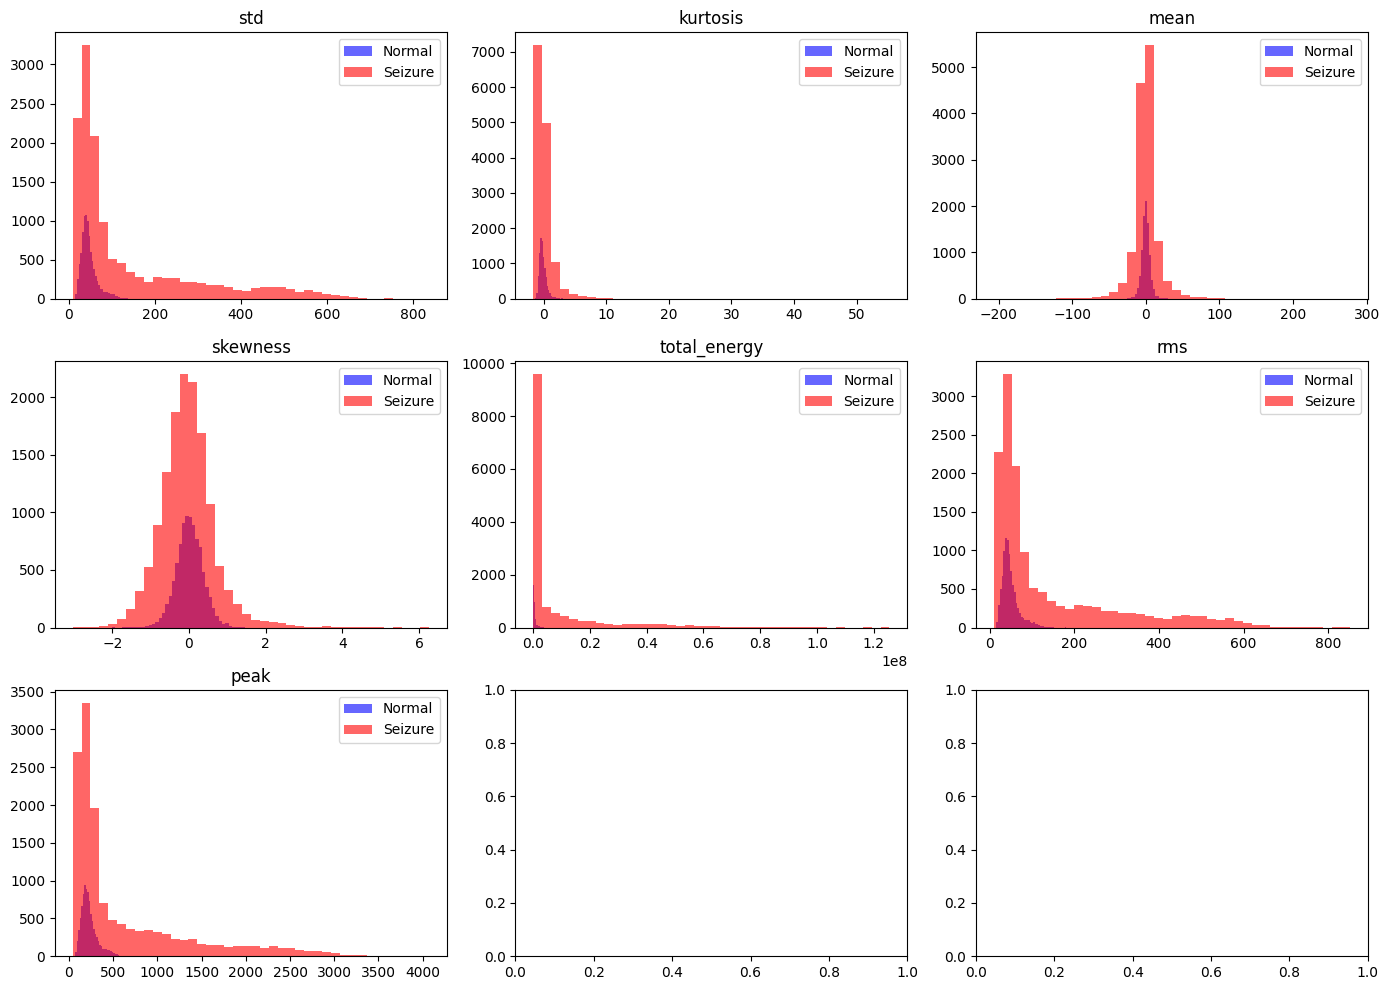

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

features_to_check = [
    'std', 'kurtosis', 'mean','skewness',
     'total_energy',
    'rms', 'peak'
]

for i, feat in enumerate(features_to_check):
    normal  = features_df1[features_df1['label'] == 0][feat]
    seizure = features_df1[features_df1['label'] == 1][feat]

    axes[i].hist(normal,  bins=40, alpha=0.6, label='Normal',  color='blue')
    axes[i].hist(seizure, bins=40, alpha=0.6, label='Seizure', color='red')
    axes[i].set_title(feat)
    axes[i].legend()

plt.tight_layout()
plt.show()

#### logistic regression

In [ ]:
X = features_df1.drop("label", axis=1)
y = features_df1['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()

X_train_scaled1 = scaler.fit_transform(X_train)
X_test_scaled1 = scaler.transform(X_test)

print("Data preparation complete:")
print(f"X_train_scaled shape: {X_train_scaled1.shape}")
print(f"X_test_scaled shape: {X_test_scaled1.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled1, y_train)

y_pred = model.predict(X_test_scaled1)

accuracy1 = accuracy_score(y_test, y_pred)
report1 = classification_report(y_test, y_pred)

print(f"\nModel: Logistic Regression")
print(f"Accuracy: {accuracy1:.4f}")
print("Classification Report:")
print(report1)


Data preparation complete:
X_train_scaled shape: (16100, 8)
X_test_scaled shape: (6900, 8)
y_train shape: (16100,)
y_test shape: (6900,)

Model: Logistic Regression
Accuracy: 0.7687
Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.76      0.73      2760
           1       0.83      0.77      0.80      4140

    accuracy                           0.77      6900
   macro avg       0.76      0.77      0.76      6900
weighted avg       0.77      0.77      0.77      6900



#### SVM

In [ ]:
svm_model1=SVC(kernel='rbf',random_state=42)
svm_model1.fit(X_train_scaled1,y_train)
y_pred=svm_model1.predict(X_test_scaled1)
accuracy2=accuracy_score(y_test,y_pred)
report2=classification_report(y_test,y_pred)
print(f"\nModel:SVM")
print(f"Accuracy:{accuracy2:.4f}")
print("Classification Report:")
print(report2)


Model:SVM
Accuracy:0.7800
Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.83      0.75        60
           1       0.87      0.74      0.80        90

    accuracy                           0.78       150
   macro avg       0.78      0.79      0.78       150
weighted avg       0.80      0.78      0.78       150



### frequency domain features

In [ ]:
from scipy.signal import welch

def bandpower(signal, fs, bands):
    freqs, psd = welch(signal, fs=fs, nperseg=256)
    powers = []
    for low, high in bands:
        idx_band = np.where((freqs >= low) & (freqs <= high))
        powers.append(np.sum(psd[idx_band]))
    return powers

eeg_bands = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alpha': (8, 13),
    'beta': (13, 30),
    'gamma': (30, 40)
}

spectral_features_data = []
for sig in X_windowed:
    current_band_powers = bandpower(sig, fs=fs, bands=eeg_bands.values())
    spectral_features_data.append(current_band_powers)

spectral_features_df = pd.DataFrame(spectral_features_data, columns=[f'{band}_power' for band in eeg_bands.keys()])
display(spectral_features_df.head())
print(spectral_features_df.shape)

/tmp/ipykernel_440/2905871865.py:4: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 173, using nperseg = 173
  freqs, psd = welch(signal, fs=fs, nperseg=256)


,delta_power,theta_power,alpha_power,beta_power,gamma_power
0,250.023939,168.553291,148.283634,121.271681,4.219139
1,482.709111,523.917107,116.585880,150.978023,5.515953
2,557.571772,145.208539,911.479945,138.681946,13.603575
3,856.348565,542.419018,252.355959,109.127113,4.291444
4,432.394577,184.495743,176.662752,324.750483,9.397067


(23000, 5)


In [ ]:
combined_features_df = pd.concat([features_df1.drop(columns=['label']), spectral_features_df], axis=1)

combined_features_df['label'] = y_windowed

display(combined_features_df.head())
print(combined_features_df.shape)

,mean,std,varience,skewness,kurtosis,rms,peak,total_energy,delta_power,theta_power,alpha_power,beta_power,gamma_power,label
0,1.695025,28.563592,815.878764,-0.054984,-0.756096,28.613841,124.615725,141644.074348,250.023939,168.553291,148.283634,121.271681,4.219139,0
1,-1.203154,32.818686,1077.066153,0.234455,-0.569209,32.840733,144.957686,186582.875879,482.709111,523.917107,116.585880,150.978023,5.515953,0
2,3.850734,40.568673,1645.817204,-0.179674,-0.653110,40.751017,181.567837,287291.646526,557.571772,145.208539,911.479945,138.681946,13.603575,0
3,-3.294509,40.452405,1636.397107,-0.186441,-0.619693,40.586339,180.102322,284974.404947,856.348565,542.419018,252.355959,109.127113,4.291444,0
4,-5.059396,31.332359,981.716702,-0.124516,0.280963,31.738213,168.455590,174265.354175,432.394577,184.495743,176.662752,324.750483,9.397067,0


(23000, 14)


#### plottings

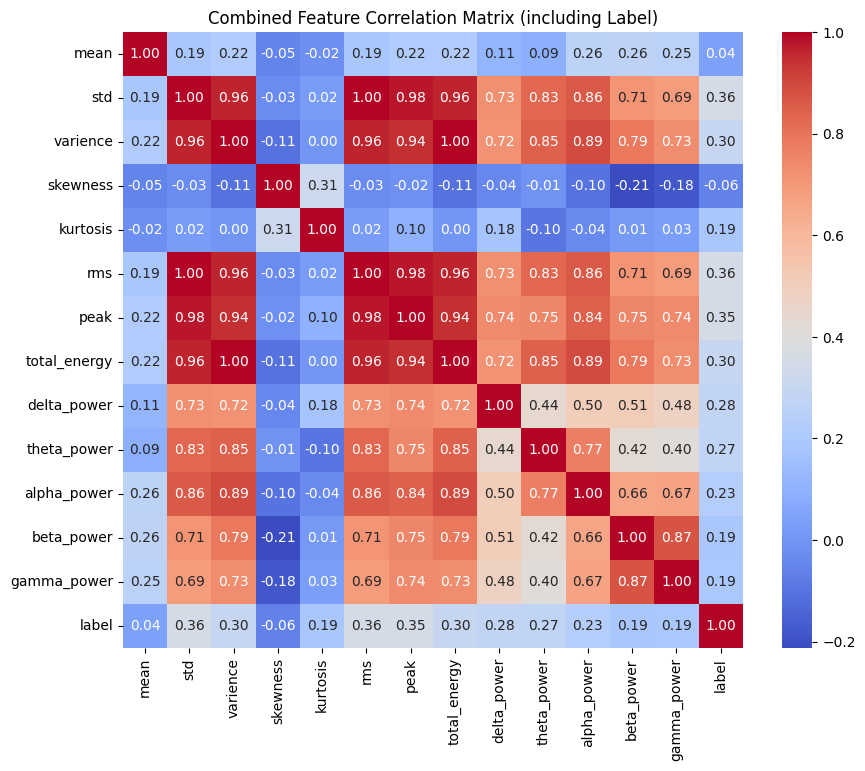

In [ ]:
corr_combined = combined_features_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_combined, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Combined Feature Correlation Matrix (including Label)')
plt.show()

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

features_to_check_combined = [
    'std', 'kurtosis', 'mean', 'skewness', 'rms', 'peak', 'total_energy',
    'delta_power', 'theta_power', 'alpha_power', 'beta_power', 'gamma_power'
]

for i, feat in enumerate(features_to_check_combined):
    if i < len(axes):
        normal_combined  = combined_features_df[combined_features_df['label'] == 0][feat]
        seizure_combined = combined_features_df[combined_features_df['label'] == 1][feat]

        axes[i].hist(normal_combined,  bins=40, alpha=0.6, label='Normal',  color='blue')
        axes[i].hist(seizure_combined, bins=40, alpha=0.6, label='Seizure', color='red')
        axes[i].set_title(feat)
        axes[i].legend()

plt.tight_layout()
plt.show()

### Continuous Wavelet Transform (CWT) Feature Extraction


In [ ]:
!pip install pywt

In [ ]:
import pywt

wavelet = 'morl'
scales = np.arange(1, 65)

fs = 173.6

cwt_features_data = []

for signal in X_windowed:

    coeffs, freqs = pywt.cwt(signal, scales, wavelet, sampling_period=1/fs)

    mean_abs_coeffs = np.mean(np.abs(coeffs), axis=1)
    std_coeffs = np.std(np.abs(coeffs), axis=1)

    features_row = list(mean_abs_coeffs) + list(std_coeffs)
    cwt_features_data.append(features_row)


    num_scales = len(scales)
    cwt_col_names = [f'cwt_mean_abs_scale_{s}' for s in scales] + \
                [f'cwt_std_scale_{s}' for s in scales]

cwt_features_df = pd.DataFrame(cwt_features_data, columns=cwt_col_names)

display(cwt_features_df.head())
print(cwt_features_df.shape)

,cwt_mean_abs_scale_1,cwt_mean_abs_scale_2,cwt_mean_abs_scale_3,cwt_mean_abs_scale_4,cwt_mean_abs_scale_5,cwt_mean_abs_scale_6,cwt_mean_abs_scale_7,cwt_mean_abs_scale_8,cwt_mean_abs_scale_9,cwt_mean_abs_scale_10,...,cwt_std_scale_55,cwt_std_scale_56,cwt_std_scale_57,cwt_std_scale_58,cwt_std_scale_59,cwt_std_scale_60,cwt_std_scale_61,cwt_std_scale_62,cwt_std_scale_63,cwt_std_scale_64
0,1.256662,0.256279,1.758742,6.335124,12.042619,16.657498,21.683378,27.040394,29.054757,30.704054,...,52.325801,52.180222,51.851372,51.547065,51.019089,50.281713,49.548667,48.916040,47.996540,47.162403
1,1.256874,0.151541,1.796398,7.046415,12.197443,14.099476,16.949947,24.042397,31.828931,40.122710,...,57.499806,55.892264,54.039703,52.228457,50.260625,48.261654,46.257410,44.149512,41.949518,40.126591
2,1.284921,0.259368,2.009323,6.769474,10.693530,10.970363,11.643001,17.891587,30.126932,46.395249,...,36.733260,37.644063,38.595521,39.718833,40.601235,41.164305,40.696077,39.744217,39.161031,38.974272
3,1.470817,0.255620,2.142898,7.115355,12.598246,17.509738,21.018540,24.747701,30.122714,36.428910,...,66.048199,65.829614,65.429724,65.009211,64.556710,64.008730,63.470817,63.005553,62.591471,62.174294
4,1.664827,0.187294,2.141440,8.418744,17.005394,23.607536,27.513256,29.917491,31.565021,35.506095,...,60.321045,60.267425,60.089024,59.419986,58.831429,58.164159,57.352237,56.522255,55.589465,54.630991


(23000, 128)


#### plottings

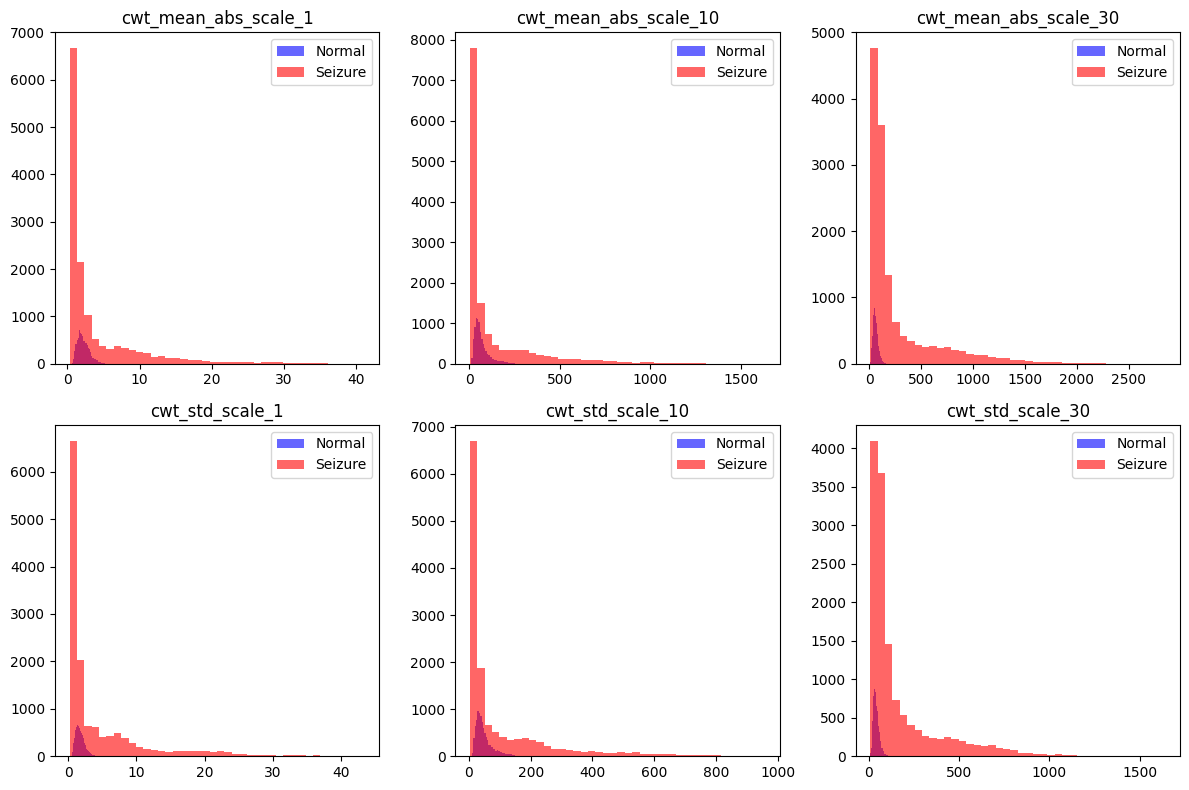

In [ ]:
import matplotlib.pyplot as plt

cwt_features_to_check = [
    'cwt_mean_abs_scale_1', 'cwt_mean_abs_scale_10', 'cwt_mean_abs_scale_30',
    'cwt_std_scale_1', 'cwt_std_scale_10', 'cwt_std_scale_30'
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i, feat in enumerate(cwt_features_to_check):
    if i < len(axes): # Ensure we don't go out of bounds for axes
        if feat in final_combined_features_df.columns:
            normal_cwt  = final_combined_features_df[final_combined_features_df['label'] == 0][feat].dropna()
            seizure_cwt = final_combined_features_df[final_combined_features_df['label'] == 1][feat].dropna()

            # Check if there's any data left after dropping NaNs
            if not normal_cwt.empty or not seizure_cwt.empty:
                axes[i].hist(normal_cwt,  bins=40, alpha=0.6, label='Normal',  color='blue')
                axes[i].hist(seizure_cwt, bins=40, alpha=0.6, label='Seizure', color='red')
                axes[i].set_title(feat)
                axes[i].legend()
            else:
                axes[i].set_title(f"{feat} (No valid data to plot)")
                axes[i].set_visible(True) # Make sure the subplot is visible to show the title
        else:
            axes[i].set_visible(False) # If feature column doesn't exist
    else:
        axes[i].set_visible(False) # For any extra axes not used by features_to_check

plt.tight_layout()
plt.show()

#### combining all features

In [ ]:
final_combined_features_df = pd.concat([combined_features_df.drop(columns=['label']), cwt_features_df], axis=1)
final_combined_features_df['label'] = y_windowed

display(final_combined_features_df.head())
print(final_combined_features_df.shape)

,mean,std,varience,skewness,kurtosis,rms,peak,total_energy,delta_power,theta_power,...,cwt_std_scale_56,cwt_std_scale_57,cwt_std_scale_58,cwt_std_scale_59,cwt_std_scale_60,cwt_std_scale_61,cwt_std_scale_62,cwt_std_scale_63,cwt_std_scale_64,label
0,1.695025,28.563592,815.878764,-0.054984,-0.756096,28.613841,124.615725,141644.074348,250.023939,168.553291,...,52.180222,51.851372,51.547065,51.019089,50.281713,49.548667,48.916040,47.996540,47.162403,0
1,-1.203154,32.818686,1077.066153,0.234455,-0.569209,32.840733,144.957686,186582.875879,482.709111,523.917107,...,55.892264,54.039703,52.228457,50.260625,48.261654,46.257410,44.149512,41.949518,40.126591,0
2,3.850734,40.568673,1645.817204,-0.179674,-0.653110,40.751017,181.567837,287291.646526,557.571772,145.208539,...,37.644063,38.595521,39.718833,40.601235,41.164305,40.696077,39.744217,39.161031,38.974272,0
3,-3.294509,40.452405,1636.397107,-0.186441,-0.619693,40.586339,180.102322,284974.404947,856.348565,542.419018,...,65.829614,65.429724,65.009211,64.556710,64.008730,63.470817,63.005553,62.591471,62.174294,0
4,-5.059396,31.332359,981.716702,-0.124516,0.280963,31.738213,168.455590,174265.354175,432.394577,184.495743,...,60.267425,60.089024,59.419986,58.831429,58.164159,57.352237,56.522255,55.589465,54.630991,0


(23000, 142)


In [ ]:
from sklearn.model_selection import train_test_split

X_final = final_combined_features_df.drop('label', axis=1)
y_final = final_combined_features_df['label']

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X_final, y_final, test_size=0.3, random_state=42, stratify=y_final)

print("Data split complete:")
print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")
print(f"y_train_final shape: {y_train_final.shape}")
print(f"y_test_final shape: {y_test_final.shape}")

Data split complete:
X_train_final shape: (16100, 141)
X_test_final shape: (6900, 141)
y_train_final shape: (16100,)
y_test_final shape: (6900,)


Re-scaling complete:
X_train_final_scaled shape: (16100, 141)
X_test_final_scaled shape: (6900, 141)

Model: Logistic Regression (Full Combined Features)
Accuracy: 0.9510
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      2760
           1       0.95      0.97      0.96      4140

    accuracy                           0.95      6900
   macro avg       0.95      0.95      0.95      6900
weighted avg       0.95      0.95      0.95      6900



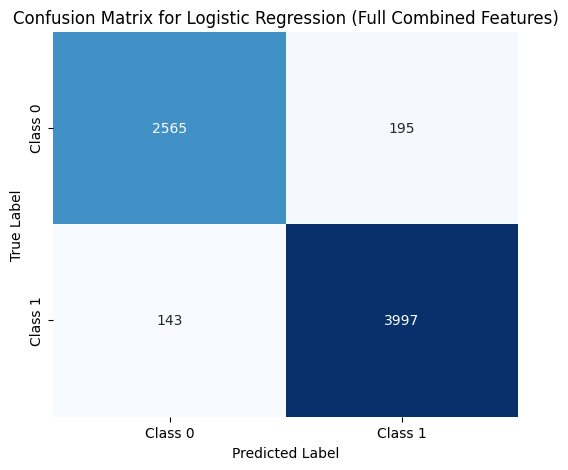


Model: SVM (Full Combined Features)
Accuracy: 0.9477
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      2760
           1       0.95      0.96      0.96      4140

    accuracy                           0.95      6900
   macro avg       0.95      0.94      0.95      6900
weighted avg       0.95      0.95      0.95      6900



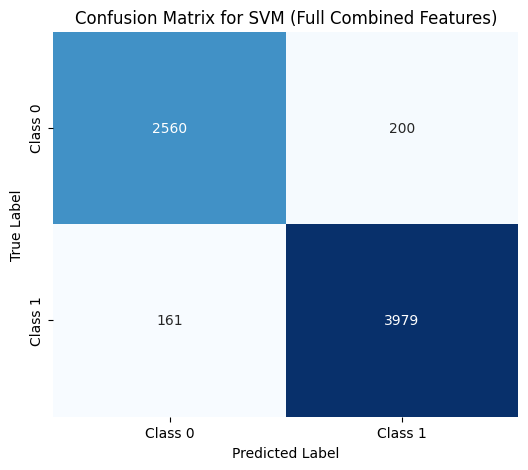

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler # Import StandardScaler

# Re-scale features to ensure consistency
scaler_final = StandardScaler()
X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_test_final_scaled = scaler_final.transform(X_test_final)

print("Re-scaling complete:")
print(f"X_train_final_scaled shape: {X_train_final_scaled.shape}")
print(f"X_test_final_scaled shape: {X_test_final_scaled.shape}")

# Train and evaluate Logistic Regression
log_reg_model_final = LogisticRegression(random_state=42, max_iter=1000)
log_reg_model_final.fit(X_train_final_scaled, y_train_final)

y_pred_log_reg_final = log_reg_model_final.predict(X_test_final_scaled)

accuracy_log_reg_final = accuracy_score(y_test_final, y_pred_log_reg_final)
report_log_reg_final = classification_report(y_test_final, y_pred_log_reg_final)

print(f"\nModel: Logistic Regression (Full Combined Features)")
print(f"Accuracy: {accuracy_log_reg_final:.4f}")
print("Classification Report:")
print(report_log_reg_final)

# Confusion Matrix for Logistic Regression
cm_log_reg_final = confusion_matrix(y_test_final, y_pred_log_reg_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_log_reg_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression (Full Combined Features)')
plt.show()

# Train and evaluate SVM
svm_model_final = SVC(kernel='rbf', random_state=42)
svm_model_final.fit(X_train_final_scaled, y_train_final)

y_pred_svm_final = svm_model_final.predict(X_test_final_scaled)

accuracy_svm_final = accuracy_score(y_test_final, y_pred_svm_final)
report_svm_final = classification_report(y_test_final, y_pred_svm_final)

print(f"\nModel: SVM (Full Combined Features)")
print(f"Accuracy: {accuracy_svm_final:.4f}")
print("Classification Report:")
print(report_svm_final)

# Confusion Matrix for SVM
cm_svm_final = confusion_matrix(y_test_final, y_pred_svm_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for SVM (Full Combined Features)')
plt.show()

#### plottings

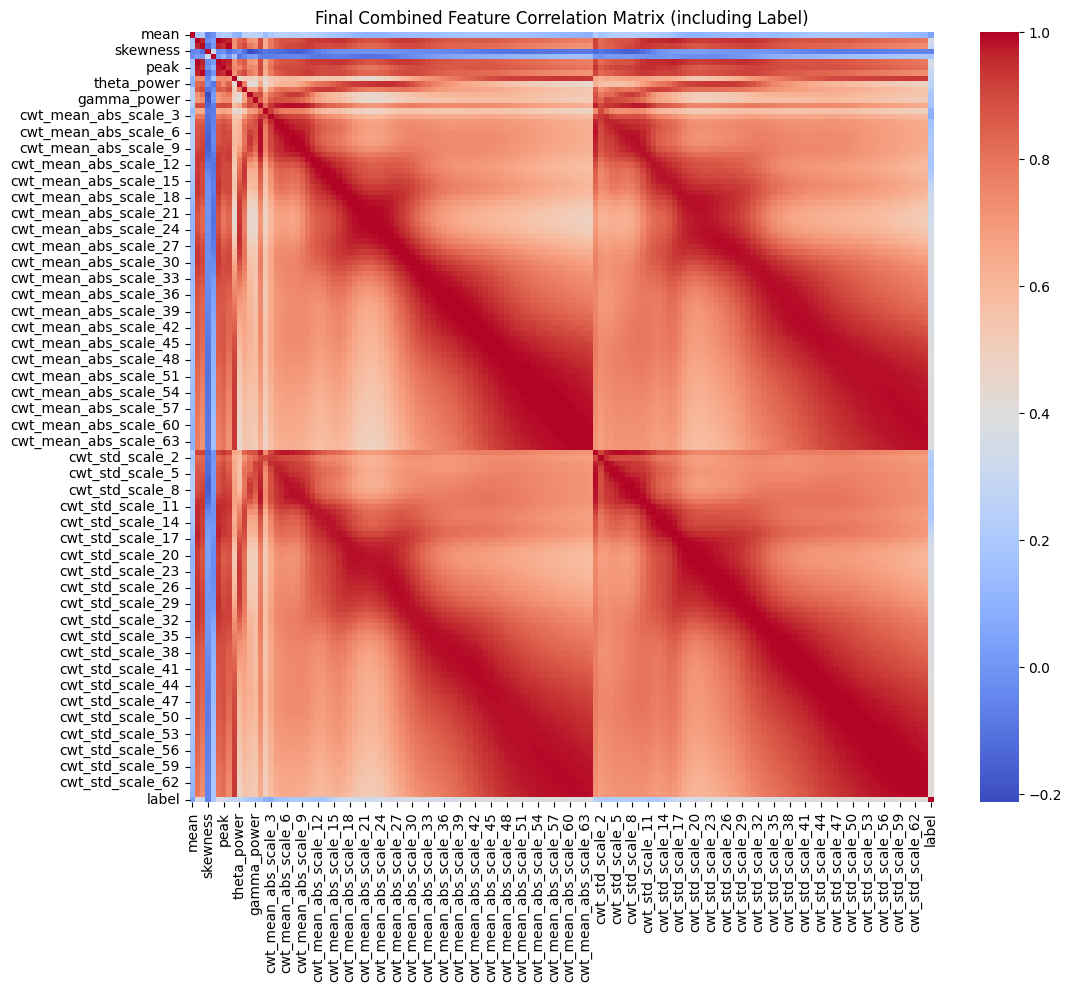

In [ ]:
corr_final_combined = final_combined_features_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_final_combined, annot=False, fmt='.2f', cmap='coolwarm')
plt.title('Final Combined Feature Correlation Matrix (including Label)')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

X_final = final_combined_features_df.drop('label', axis=1)
y_final = final_combined_features_df['label']

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X_final, y_final, test_size=0.3, random_state=42, stratify=y_final)

scaler_final = StandardScaler()
X_train_final_scaled = scaler_final.fit_transform(X_train_final)
X_test_final_scaled = scaler_final.transform(X_test_final)

print("Data preparation with combined features complete:")
print(f"X_train_final_scaled shape: {X_train_final_scaled.shape}")
print(f"X_test_final_scaled shape: {X_test_final_scaled.shape}")
print(f"y_train_final shape: {y_train_final.shape}")
print(f"y_test_final shape: {y_test_final.shape}")

Data preparation with combined features complete:
X_train_final_scaled shape: (350, 141)
X_test_final_scaled shape: (150, 141)
y_train_final shape: (350,)
y_test_final shape: (150,)


#### Logistic Regression with Combined Features


Model: Logistic Regression (Full Combined Features)
Accuracy: 0.9667
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96        60
           1       0.98      0.97      0.97        90

    accuracy                           0.97       150
   macro avg       0.96      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



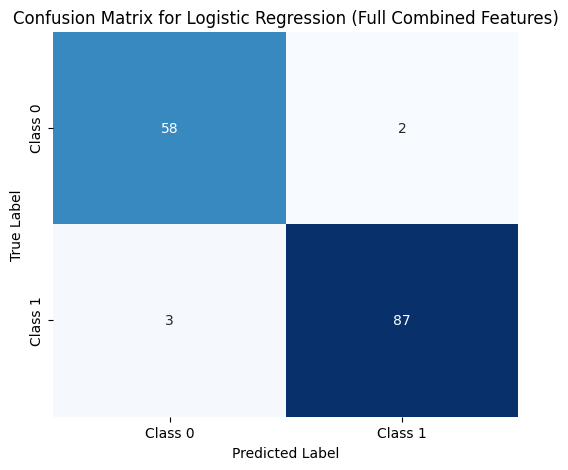

In [ ]:
# Train and evaluate Logistic Regression
log_reg_model_final = LogisticRegression(random_state=42, max_iter=1000) # Increased max_iter for convergence with more features
log_reg_model_final.fit(X_train_final_scaled, y_train_final)

y_pred_log_reg_final = log_reg_model_final.predict(X_test_final_scaled)

accuracy_log_reg_final = accuracy_score(y_test_final, y_pred_log_reg_final)
report_log_reg_final = classification_report(y_test_final, y_pred_log_reg_final)

print(f"\nModel: Logistic Regression (Full Combined Features)")
print(f"Accuracy: {accuracy_log_reg_final:.4f}")
print("Classification Report:")
print(report_log_reg_final)

# Confusion Matrix
cm_log_reg_final = confusion_matrix(y_test_final, y_pred_log_reg_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_log_reg_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression (Full Combined Features)')
plt.show()

#### SVM with Combined Features


Model: SVM (Full Combined Features)
Accuracy: 0.9733
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        60
           1       0.98      0.98      0.98        90

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



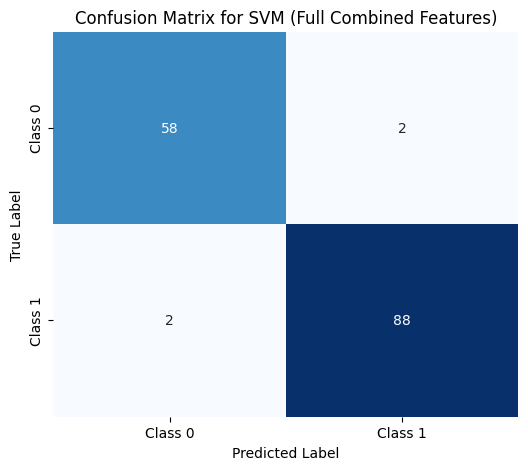

In [ ]:
# Train and evaluate SVM
svm_model_final = SVC(kernel='rbf', random_state=42)
svm_model_final.fit(X_train_final_scaled, y_train_final)

y_pred_svm_final = svm_model_final.predict(X_test_final_scaled)

accuracy_svm_final = accuracy_score(y_test_final, y_pred_svm_final)
report_svm_final = classification_report(y_test_final, y_pred_svm_final)

print(f"\nModel: SVM (Full Combined Features)")
print(f"Accuracy: {accuracy_svm_final:.4f}")
print("Classification Report:")
print(report_svm_final)

# Confusion Matrix
cm_svm_final = confusion_matrix(y_test_final, y_pred_svm_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for SVM (Full Combined Features)')
plt.show()

#### Cross-Validation with Combined Features

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

scaler_cv_final = StandardScaler()
X_scaled_cv_final = scaler_cv_final.fit_transform(X_final)

skf_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Setup complete for cross-validation with combined features.")

log_reg_model_cv_final = LogisticRegression(random_state=42, max_iter=1000)
cv_scores_log_reg_final = cross_val_score(log_reg_model_cv_final, X_scaled_cv_final, y_final, cv=skf_final, scoring='accuracy')

print("\nLogistic Regression Cross-Validation Scores (Full Combined Features):", cv_scores_log_reg_final)
print(f"Mean Accuracy (Logistic Regression, Full Combined Features): {cv_scores_log_reg_final.mean():.4f}")
print(f"Standard Deviation (Logistic Regression, Full Combined Features): {cv_scores_log_reg_final.std():.4f}")

svm_model_cv_final = SVC(kernel='rbf', random_state=42)
cv_scores_svm_final = cross_val_score(svm_model_cv_final, X_scaled_cv_final, y_final, cv=skf_final, scoring='accuracy')

print("\nSVM Cross-Validation Scores (Full Combined Features):", cv_scores_svm_final)
print(f"Mean Accuracy (SVM, Full Combined Features): {cv_scores_svm_final.mean():.4f}")
print(f"Standard Deviation (SVM, Full Combined Features): {cv_scores_svm_final.std():.4f}")

Setup complete for cross-validation with combined features.

Logistic Regression Cross-Validation Scores (Full Combined Features): [0.97 0.98 0.98 0.97 0.95]
Mean Accuracy (Logistic Regression, Full Combined Features): 0.9700
Standard Deviation (Logistic Regression, Full Combined Features): 0.0110

SVM Cross-Validation Scores (Full Combined Features): [0.94 0.97 1.   0.99 0.94]
Mean Accuracy (SVM, Full Combined Features): 0.9680
Standard Deviation (SVM, Full Combined Features): 0.0248


### Pairplot of Most Correlated Features in `features_df1`

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the absolute correlations with the 'label' in features_df1
correlations_with_label = features_df1.corr()['label'].abs().sort_values(ascending=False)

# Select the top 5 most correlated features (excluding the 'label' itself)
top_correlated_features = correlations_with_label[1:6].index.tolist()

# Add the 'label' back for the pairplot coloring
features_for_pairplot = features_df1[top_correlated_features + ['label']]

# Create the pairplot
plt.figure(figsize=(12, 10))
sns.pairplot(features_for_pairplot, hue='label', palette='viridis', diag_kind='kde')
plt.suptitle('Pairplot of Top 5 Features Most Correlated with Label (features_df1)', y=1.02) # Adjust suptitle position
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

### Persisting Data to Google Drive

To ensure your uploaded files or processed data persists across sessions, save them to your mounted Google Drive. First, let's create a directory in your Drive where you can store these files. Then, we'll save your dataframes (`df1` to `df5`) as CSV files to this new directory.

In [ ]:
import os

# Define the path to your Google Drive
drive_path = '/content/drive/My Drive/'

# Define a folder name for your data (you can change this)
data_folder = 'bonn_eeg_data'

# Create the full path for the data folder
full_data_path = os.path.join(drive_path, data_folder)

# Check if the folder exists, if not, create it
if not os.path.exists(full_data_path):
    os.makedirs(full_data_path)
    print(f"Created directory: {full_data_path}")
else:
    print(f"Directory already exists: {full_data_path}")


In [ ]:
# Save each DataFrame to Google Drive as a CSV file
df_names = ['df1', 'df2', 'df3', 'df4', 'df5']

for i, df_name in enumerate(df_names):
    # Get the DataFrame from its global name
    current_df = globals()[df_name]

    # Define the filename (e.g., setA_bonn.csv, setB_bonn.csv)
    filename = f"set{chr(65+i)}_bonn.csv"

    # Construct the full file path
    file_path = os.path.join(full_data_path, filename)

    # Save the DataFrame to CSV
    current_df.to_csv(file_path, index=False)
    print(f"Saved {df_name} to {file_path}")

print("All dataframes saved to Google Drive.")

### Loading Data from Google Drive

In a new session, after mounting Google Drive, you can load your dataframes directly from the saved CSV files in your Drive folder.

In [ ]:
# Example of how to load the dataframes back from Google Drive
loaded_dfs = {}
for i, df_name in enumerate(df_names):
    filename = f"set{chr(65+i)}_bonn.csv"
    file_path = os.path.join(full_data_path, filename)
    loaded_dfs[df_name] = pd.read_csv(file_path)
    print(f"Loaded {df_name} from {file_path}")

# You can access them like loaded_dfs['df1'], loaded_dfs['df2'], etc.
# For example, let's display the head of the first loaded dataframe:
print("\nFirst loaded dataframe (df1) head:")
display(loaded_dfs['df1'].head())